In [1]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('04_bank_customers.csv', sep=';')

# Menampilkan 5 data pertama
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menampilkan jumlah baris dan kolom
print("Jumlah Baris dan Kolom:", df.shape)

# Menampilkan jumlah baris
print("Jumlah Data:", df.shape[0])

# Menampilkan jumlah atribut
print("Jumlah Atribut:", df.shape[1])


Jumlah Baris dan Kolom: (45211, 17)
Jumlah Data: 45211
Jumlah Atribut: 17


In [3]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menampilkan informasi struktur dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menampilkan statistik deskriptif
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [5]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Memeriksa jumlah missing values setiap kolom
print("Missing Values Setiap Kolom:")
print(df.isnull().sum())

# Menghitung total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values Setiap Kolom:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total Missing Values: 0


In [6]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menghitung jumlah data duplikat
print("Jumlah Data Duplikat:", df.duplicated().sum())


Jumlah Data Duplikat: 0


In [7]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menghitung jumlah setiap kelas target
print("Distribusi Target:")
print(df['y'].value_counts())

# Menghitung persentase setiap kelas target
print("\nPersentase Target:")
print(df['y'].value_counts(normalize=True) * 100)


Distribusi Target:
no     39922
yes     5289
Name: y, dtype: int64

Persentase Target:
no     88.30152
yes    11.69848
Name: y, dtype: float64


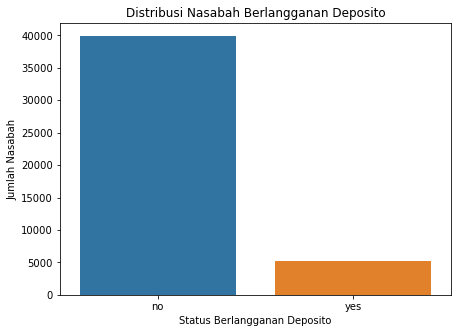

In [8]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Membuat visualisasi distribusi target
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Distribusi Nasabah Berlangganan Deposito')
plt.xlabel('Status Berlangganan Deposito')
plt.ylabel('Jumlah Nasabah')

plt.show()


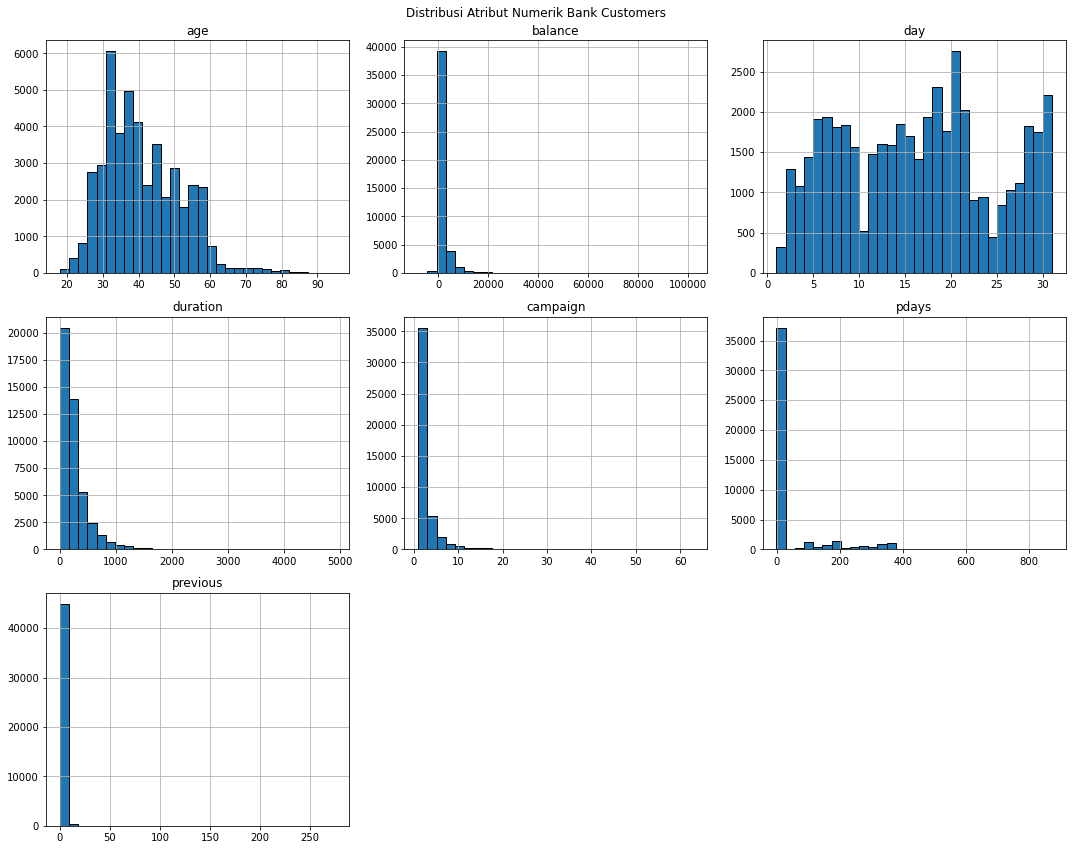

In [9]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Memilih atribut numerik
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Membuat histogram setiap atribut numerik
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribusi Atribut Numerik Bank Customers')
plt.tight_layout()
plt.show()


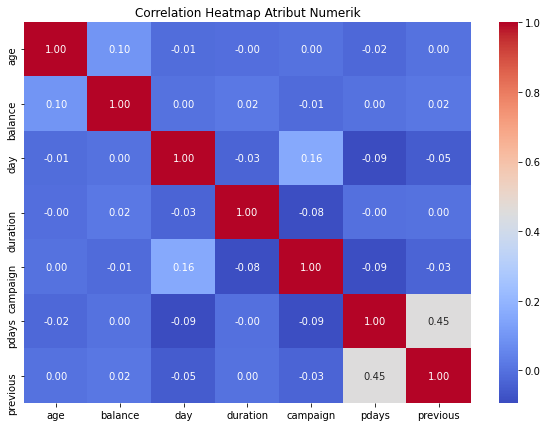

In [10]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Mengambil atribut numerik
numerical_df = df.select_dtypes(include=['int64', 'float64'])

# Menghitung korelasi
correlation = numerical_df.corr()

# Membuat heatmap korelasi
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap Atribut Numerik')
plt.show()


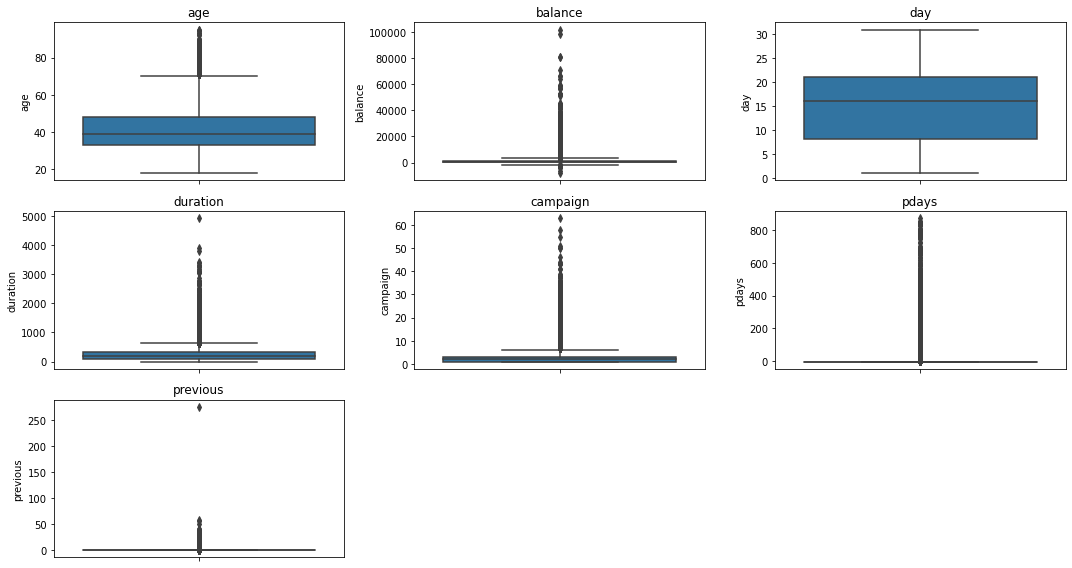

In [11]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Membuat boxplot atribut numerik
plt.figure(figsize=(15, 8))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()


In [12]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Memisahkan atribut numerik dan kategorikal
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object']
).drop(columns=['y']).columns.tolist()

print("Atribut Numerik:")
print(numerical_features)

print("\nAtribut Kategorikal:")
print(categorical_features)

print("\nAtribut Target:")
print("y")


Atribut Numerik:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Atribut Kategorikal:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Atribut Target:
y


In [13]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menghitung outliers menggunakan metode IQR
for column in numerical_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers")


age: 487 outliers
balance: 4729 outliers
day: 0 outliers
duration: 3235 outliers
campaign: 3064 outliers
pdays: 8257 outliers
previous: 8257 outliers


In [14]:

#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Memisahkan fitur dan target
X = df.drop(columns=['y'])
y = df['y']

print("Jumlah Fitur:", X.shape)
print("Jumlah Target:", y.shape)

print("\nContoh Fitur:")
display(X.head())

print("\nContoh Target:")
display(y.head())


Jumlah Fitur: (45211, 16)
Jumlah Target: (45211,)

Contoh Fitur:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown



Contoh Target:


0    no
1    no
2    no
3    no
4    no
Name: y, dtype: object

In [15]:

#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.model_selection import train_test_split

# Membagi data dengan perbandingan 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", X_train.shape[0])
print("Jumlah Data Testing:", X_test.shape[0])

print("\nDistribusi Target Training:")
print(y_train.value_counts())

print("\nDistribusi Target Testing:")
print(y_test.value_counts())


Jumlah Data Training: 36168
Jumlah Data Testing: 9043

Distribusi Target Training:
no     31937
yes     4231
Name: y, dtype: int64

Distribusi Target Testing:
no     7985
yes    1058
Name: y, dtype: int64


In [16]:

#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Membuat preprocessing untuk atribut numerik dan kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Melakukan preprocessing pada data training dan testing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Bentuk Data Training Setelah Preprocessing:",
      X_train_processed.shape)

print("Bentuk Data Testing Setelah Preprocessing:",
      X_test_processed.shape)


Bentuk Data Training Setelah Preprocessing: (36168, 51)
Bentuk Data Testing Setelah Preprocessing: (9043, 51)


In [17]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.naive_bayes import GaussianNB

# Membuat model Gaussian Naive Bayes
model_nb = GaussianNB()

# Melatih model menggunakan data training
model_nb.fit(X_train_processed, y_train)

print("Model Gaussian Naive Bayes berhasil dilatih.")

Model Gaussian Naive Bayes berhasil dilatih.


In [18]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Melakukan prediksi terhadap data testing
y_pred_nb = model_nb.predict(X_test_processed)

print("Hasil prediksi Naive Bayes:")
print(y_pred_nb[:20])

Hasil prediksi Naive Bayes:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'yes' 'no']


In [19]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.neighbors import KNeighborsClassifier

# Membuat model KNN dengan 5 tetangga terdekat
model_knn = KNeighborsClassifier(n_neighbors=5)

# Melatih model
model_knn.fit(X_train_processed, y_train)

print("Model KNN berhasil dilatih.")

Model KNN berhasil dilatih.


In [20]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Melakukan prediksi terhadap data testing
y_pred_knn = model_knn.predict(X_test_processed)

print("Hasil prediksi KNN:")
print(y_pred_knn[:20])

Hasil prediksi KNN:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no']


In [21]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Menghitung akurasi
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Akurasi Naive Bayes:", accuracy_nb)
print("\nClassification Report Naive Bayes:")
print(classification_report(y_test, y_pred_nb))

print("Confusion Matrix Naive Bayes:")
print(confusion_matrix(y_test, y_pred_nb))

Akurasi Naive Bayes: 0.8548048214088245

Classification Report Naive Bayes:
              precision    recall  f1-score   support

          no       0.93      0.90      0.92      7985
         yes       0.41      0.52      0.46      1058

    accuracy                           0.85      9043
   macro avg       0.67      0.71      0.69      9043
weighted avg       0.87      0.85      0.86      9043

Confusion Matrix Naive Bayes:
[[7180  805]
 [ 508  550]]


In [22]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

# Menghitung akurasi
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("Akurasi KNN:", accuracy_knn)
print("\nClassification Report KNN:")
print(classification_report(y_test, y_pred_knn))

print("Confusion Matrix KNN:")
print(confusion_matrix(y_test, y_pred_knn))

Akurasi KNN: 0.8961627778392126

Classification Report KNN:
              precision    recall  f1-score   support

          no       0.92      0.97      0.94      7985
         yes       0.60      0.34      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.66      0.69      9043
weighted avg       0.88      0.90      0.88      9043

Confusion Matrix KNN:
[[7744  241]
 [ 698  360]]


In [23]:
#202431111_RendyPradikaAbiyoga
# NIM : 202431111
# Nama : Rendy Pradika Abiyoga

from sklearn.metrics import precision_score, recall_score, f1_score

# Membuat tabel perbandingan
hasil_perbandingan = pd.DataFrame({
    'Algoritma': ['Gaussian Naive Bayes', 'K-Nearest Neighbors'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_knn)
    ],
    'Precision (Yes)': [
        precision_score(y_test, y_pred_nb, pos_label='yes', zero_division=0),
        precision_score(y_test, y_pred_knn, pos_label='yes', zero_division=0)
    ],
    'Recall (Yes)': [
        recall_score(y_test, y_pred_nb, pos_label='yes', zero_division=0),
        recall_score(y_test, y_pred_knn, pos_label='yes', zero_division=0)
    ],
    'F1-Score (Yes)': [
        f1_score(y_test, y_pred_nb, pos_label='yes', zero_division=0),
        f1_score(y_test, y_pred_knn, pos_label='yes', zero_division=0)
    ]
})

hasil_perbandingan

,Algoritma,Accuracy,Precision (Yes),Recall (Yes),F1-Score (Yes)
0,Gaussian Naive Bayes,0.854805,0.405904,0.519849,0.455864
1,K-Nearest Neighbors,0.896163,0.599002,0.340265,0.433996
